# Bassez et al. 2021 — Breast Cancer (10x)

**02 — Manifold.** Match the scFates method to the topology (curve for non-branching), scope the fit to the developmental **Body**, derive the root from the signatures' developmental order (Gast/pSom EARLY → root; Crest LATE), infer pseudotime, and confirm the fitted curve is fold-free.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scFates as scf
import scipy.sparse as sp
from scipy.stats import spearmanr
from scipy.sparse.csgraph import shortest_path
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells |', adata.obs['compartment'].value_counts().to_dict())
xy = adata.obsm['X_umap']; c0 = xy - xy.mean(0)
from numpy.linalg import svd
_,s,_ = svd(c0, full_matrices=False)
print('whole-manifold UMAP principal-axis ratio: %.2f' % (s[0]/s[1]))

whole malignant manifold: 65837 cells | {'Body': 65837}
whole-manifold UMAP principal-axis ratio: 1.20


### Topology check — does the manifold branch?
Fit a curve (non-branching) and inspect tips/forks and the fold self-approach ratio (>1 = fold-free) across node counts. A curve (not tree) is the right primitive when there is no clean bifurcation; the fold check guards against re-embedding artefacts.

In [4]:
def _fold(ad):
    B=np.asarray(ad.uns['graph']['B']); F=ad.uns['graph']['F'].T
    G=shortest_path(sp.csr_matrix((B>0).astype(int)),unweighted=True); dmin=np.inf
    for a in range(F.shape[0]):
        for b in range(a+1,F.shape[0]):
            if G[a,b]>=3: dmin=min(dmin,np.sqrt(((F[a]-F[b])**2).sum()))
    ii,jj=np.where(np.triu(B>0)); med=np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    return dmin/med, int(((B>0).sum(0)==1).sum()), int(((B>0).sum(0)>=3).sum())
def _tip_bio(ad):
    B=np.asarray(ad.uns['graph']['B']); tps=np.where((B>0).sum(0)==1)[0]
    hard=np.asarray(ad.obsm['X_R']).argmax(1); D=shortest_path(sp.csr_matrix((B>0).astype(int)),unweighted=True)
    info={}
    for tp in tps:
        m=np.isin(hard,np.where(D[tp]<=3)[0])
        info[tp]=dict(Gast=ad.obs['Gast_sm'][m].mean(),pSom=ad.obs['pSom_sm'][m].mean(),
                      Crest=ad.obs['Crest_sm'][m].mean(),cyc=ad.obs['cycling'][m].mean())
    return tps,info

### Why scope to the Body — proliferation-confound control
If a Cycling compartment was flagged in 01, a curve fit on the *whole* manifold roots at a cycling tip and its pseudotime tracks proliferation. That control is shown, then the trajectory is scoped to the developmental Body. If no Cycling compartment exists, the Body is the whole manifold.

In [5]:
has_cyc = (adata.obs['compartment']=='Cycling').any()
if has_cyc:
    ctrl = adata.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(ctrl, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
        tps,info = _tip_bio(ctrl)
        root_w = int(max(tps, key=lambda tp: info[tp]['Gast']+info[tp]['pSom']-info[tp]['Crest']))
        scf.tl.root(ctrl, root_w); scf.tl.pseudotime(ctrl, n_map=1, seed=SEED)
    rho_w,_ = spearmanr(ctrl.obs['t'], ctrl.obs['prolif_score'])
    print(f'WHOLE-manifold control: root tip {root_w} is {info[root_w]["cyc"]*100:.0f}% cycling; '
          f'pseudotime vs proliferation rho = {rho_w:+.2f} (proliferation-driven -> scope out Cycling)')
else:
    print('no Cycling compartment flagged in 01 -> Body is the whole manifold; no scoping needed')

no Cycling compartment flagged in 01 -> Body is the whole manifold; no scoping needed


### Scope to the developmental Body and fit the curve
Fold-free curve over the Body; assert no forks (non-branching) and self-approach >1 (fold-free).

In [6]:
sub = adata[adata.obs['compartment']=='Body'].copy()
xy=sub.obsm['X_umap']; cc=xy-xy.mean(0); _,ss,_=np.linalg.svd(cc,full_matrices=False)
print('Body:', sub.shape[0], 'cells | UMAP axis ratio %.2f' % (ss[0]/ss[1]))
for Nn in [15,20,30]:
    a2=sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(a2, Nodes=Nn, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa,tips,forks=_fold(a2); print(f'curve N={Nn}: {tips} tips, {forks} forks | self-approach {sa:.2f}')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa,tips,forks=_fold(sub)
print(f'chosen curve N=20: {tips} tips, {forks} forks | fold self-approach = {sa:.2f} (>1 = fold-free)')
assert forks==0 and sa>1, 'topology check failed'

Body: 65837 cells | UMAP axis ratio 1.20
curve N=15: 2 tips, 0 forks | self-approach 2.82
curve N=20: 2 tips, 0 forks | self-approach 2.53
curve N=30: 2 tips, 0 forks | self-approach 2.05
chosen curve N=20: 2 tips, 0 forks | fold self-approach = 2.53 (>1 = fold-free)


### Derive the root and infer pseudotime
Root at the Gast/pSom-high, Crest-low tip (developmental origin — Gast/pSom are EARLY, Crest LATE). Report module gradients along pseudotime and the cell-cycle caveat.

In [7]:
B=np.asarray(sub.uns['graph']['B']); tps=np.where((B>0).sum(0)==1)[0]
hard=np.asarray(sub.obsm['X_R']).argmax(1); D=shortest_path(sp.csr_matrix((B>0).astype(int)),unweighted=True)
info={}
for tp in tps:
    m=np.isin(hard,np.where(D[tp]<=3)[0])
    info[tp]=(sub.obs['Gast_sm'][m].mean(),sub.obs['pSom_sm'][m].mean(),sub.obs['Crest_sm'][m].mean(),sub.obs['cycling'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f} cycling={info[tp][3]:.2f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low; %.0f%% cycling)' % (info[root][3]*100))
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values; tn=(t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for sname in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p=spearmanr(t, sub.obs[sname]); print(f'  {sname}: rho={rho:+.3f} p={p:.1e}')
for m,lab in [('Crest_sm','Neural-crest'),('pSom_sm','Somitogenesis'),('Gast_sm','Gastrulation')]:
    hi=sub.obs[m]>=sub.obs[m].quantile(0.9); print(f'{lab}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')
rho_c,_=spearmanr(t, sub.obs['prolif_score'])
print(f'caveat: pseudotime vs proliferation score rho = {rho_c:+.2f} (cell-cycle-free axis)')

tip 0: Gast=-0.0151 pSom=+0.0122 Crest=+0.0046 cycling=0.04
tip 2: Gast=-0.0152 pSom=+0.0245 Crest=-0.0046 cycling=0.03
derived root = tip 2 (Gast/pSom-high, Crest-low; 3% cycling)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.113 p=2.1e-186
  pSom_sm: rho=-0.316 p=0.0e+00
  Crest_sm: rho=+0.323 p=0.0e+00
Neural-crest-high decile mean pseudotime = 0.40
Somitogenesis-high decile mean pseudotime = 0.41
Gastrulation-high decile mean pseudotime = 0.23
caveat: pseudotime vs proliferation score rho = -0.24 (cell-cycle-free axis)


### Map pseudotime back to the whole manifold and save

In [8]:
adata.obs['t'] = np.nan
adata.obs.loc[sub.obs_names, 't'] = sub.obs['t'].values
adata.uns['root'] = int(root); adata.uns['geometry'] = 'non-branching (curve)'
adata.uns['curve_nodes'] = np.asarray(sub.uns['graph']['F']).T
adata.write(os.path.join(pth_out, 'manifold.h5ad'))
print('saved manifold.h5ad | t defined on', int(adata.obs["t"].notna().sum()), 'Body cells')

saved manifold.h5ad | t defined on 65837 Body cells


### Figure — pseudotime manifold (`manifold.pdf`)
House linear layout; Body cells coloured by pseudotime, any Cycling cells greyed.

saved manifold.pdf


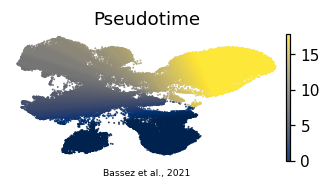

In [9]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi=np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi=np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, size=6, alpha=.5, frameon=False, show=False, ax=ax, na_color='lightgray')
body = plot[plot.obs['t'].notna()].copy()
sc.pl.umap(body, color='t', cmap='cividis', size=6, alpha=.85, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Bassez et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.pdf')